In [7]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
DATA_DIR = Path("results")
DEFAULT_N_CHANNELS = 72

'''
file format expected :
- tones : mesure_[distance]m_[los/nlos]_[nbr_channel]_channel_[optional_tag].csv
- procedures : mesure_[distance]m_[los/nlos]_[nbr_channel]_channel_[optional_tag].csv
'''

FILENAME_RE = re.compile(
    r"^mesure_(?P<dist>\d+(?:_\d+)?)m_(?P<env>los|nlos)"
    r"(?:_(?P<n_channels>\d+)_channel)?"
    r"(?P<tag>(?:_[a-z]+)*?)"
    r"(?P<procedures>_procedures)?\.csv$"
)

def parse_filename(path: Path) -> dict | None:
    m = FILENAME_RE.match(path.name)
    if m is None:
        return None
    tag = m["tag"].lstrip("_")
    return {
        "file": path.name,
        "kind": "procedures" if m["procedures"] else "tones",
        "session": path.name.removesuffix(".csv").removesuffix("_procedures"),
        "true_distance_m": float(m["dist"].replace("_", ".")),
        "environment": m["env"].upper(),
        "n_channels": int(m["n_channels"]) if m["n_channels"] else DEFAULT_N_CHANNELS,
        "tag": tag,  # ex. "bis"
    }

files = pd.DataFrame([p for f in sorted(DATA_DIR.glob("mesure_*.csv")) if (p := parse_filename(f))])
unparsed = [f.name for f in DATA_DIR.glob("mesure_*.csv") if parse_filename(f) is None]
if unparsed:
    print("Unknown file format :", unparsed)

In [13]:
# Verify if both tones and procedures files are present
pairing = files.pivot_table(index="session", columns="kind", values="file", aggfunc="first")
orphans = pairing[pairing.isna().any(axis=1)]
if len(orphans):
    print("Uncompleted session (tones or procedures file is missing) :")
    display(orphans)

In [14]:
files.drop(columns="file").drop_duplicates("session").sort_values(["environment", "true_distance_m", "n_channels"]).reset_index(drop=True)

,kind,session,true_distance_m,environment,n_channels,tag
0,tones,mesure_0_5m_los_72_channel,0.5,LOS,72,
1,tones,mesure_1m_los_72_channel,1.0,LOS,72,
2,tones,mesure_1_5m_los_72_channel,1.5,LOS,72,
3,tones,mesure_2m_los_72_channel,2.0,LOS,72,
4,tones,mesure_2_5m_los_72_channel,2.5,LOS,72,
5,tones,mesure_3m_los_72_channel,3.0,LOS,72,
6,tones,mesure_3_5m_los_72_channel,3.5,LOS,72,
7,tones,mesure_4m_los_37_channel,4.0,LOS,37,
8,tones,mesure_4m_los_72_channel,4.0,LOS,72,
9,tones,mesure_4_5m_los_72_channel,4.5,LOS,72,


In [20]:
META_COLS = ["session", "true_distance_m", "environment", "n_channels", "tag"]

def load_all(kind: str) -> pd.DataFrame:
    frames = []
    for _, row in files[files["kind"] == kind].iterrows():
        df = pd.read_csv(DATA_DIR / row["file"])
        for c in META_COLS:
            df.insert(META_COLS.index(c), c, row[c])
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

procedures = load_all("procedures")
tones = load_all("tones")

METHODS = {
    "dist_ifft_m": "IFFT",
    "dist_phase_slope_m": "Phase slope",
    "dist_rtt_m": "RTT",
}


for col in METHODS:
    err = procedures[col] - procedures["true_distance_m"]
    procedures[col.replace("_m", "_error_m")] = err
    procedures[col.replace("_m", "_abs_error_m")] = err.abs()

df_global = procedures.melt(
    id_vars=META_COLS + ["ranging_counter", "ap", "tone_quality", "rssi_dbm", "rtt_count"],
    value_vars=list(METHODS),
    var_name="method",
    value_name="estimated_distance_m",
)

df_global["method"] = df_global["method"].map(METHODS)
df_global["error_m"] = df_global["estimated_distance_m"] - df_global["true_distance_m"]
df_global["abs_error_m"] = df_global["error_m"].abs()
df_global.to_csv("all_procedures.csv", index=False)
df_global.head(100)

,session,true_distance_m,environment,n_channels,tag,ranging_counter,ap,tone_quality,rssi_dbm,rtt_count,method,estimated_distance_m,error_m,abs_error_m
0,mesure_0_5m_los_72_channel,0.5,LOS,72,,1615,0,OK,-40.3,18,IFFT,1.171,0.671,0.671
1,mesure_0_5m_los_72_channel,0.5,LOS,72,,1621,0,OK,-40.9,24,IFFT,1.171,0.671,0.671
2,mesure_0_5m_los_72_channel,0.5,LOS,72,,1627,0,OK,-40.6,20,IFFT,1.171,0.671,0.671
3,mesure_0_5m_los_72_channel,0.5,LOS,72,,1633,0,OK,-41.1,21,IFFT,1.171,0.671,0.671
4,mesure_0_5m_los_72_channel,0.5,LOS,72,,1639,0,OK,-40.8,19,IFFT,1.171,0.671,0.671
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,mesure_1_5m_nlos_72_channel,1.5,NLOS,72,,1134,0,OK,-63.3,19,IFFT,2.704,1.204,1.204
96,mesure_1_5m_nlos_72_channel,1.5,NLOS,72,,1140,0,OK,-62.3,18,IFFT,2.681,1.181,1.181
97,mesure_1_5m_nlos_72_channel,1.5,NLOS,72,,1145,0,OK,-62.1,19,IFFT,2.733,1.233,1.233
98,mesure_1_5m_nlos_72_channel,1.5,NLOS,72,,1150,0,OK,-62.3,20,IFFT,2.904,1.404,1.404


In [25]:
ENVIRONMENT = "LOS"
ONLY_OK_TONES = True
EXCLUDE_TAGS: set[str] = set()
DROP_ZERO_PHASE_SLOPE = True

d = df_global.dropna(subset=["estimated_distance_m"]).copy()
if ENVIRONMENT:
    d = d[d["environment"] == ENVIRONMENT]
if EXCLUDE_TAGS:
    d = d[~d["tag"].isin(EXCLUDE_TAGS)]
if DROP_ZERO_PHASE_SLOPE:
    d = d[~((d["method"] == "Phase slope") & (d["estimated_distance_m"] == 0))]
if ONLY_OK_TONES:
    d = d[(d["method"] == "RTT") | (d["tone_quality"] == "OK")]

CHANNEL_COUNTS = sorted(d["n_channels"].unique())

CH_COLORS = { 37: "#eb6834", 72: "#1baf7a"}
CH_MARKERS = { 37: "^", 72: "o"}
METHOD_ORDER = list(METHODS.values())

print(f"Channels count : {CHANNEL_COUNTS}")
pd.crosstab(d["true_distance_m"], d["n_channels"], values=d["session"], aggfunc="nunique").fillna(0).astype(int).rename_axis(
    index="Ground truth distance (m)", columns="channel count")

Channels count : [np.int64(37), np.int64(72)]


channel count,37,72
Ground truth distance (m),,
0.5,0,1
1.0,0,1
1.5,0,1
2.0,0,1
2.5,0,1
3.0,0,1
3.5,0,1
4.0,1,1
4.5,0,1


In [51]:
def q25(x): return x.quantile(0.25)
def q75(x): return x.quantile(0.75)

stats = (
    d.groupby(["method", "n_channels", "true_distance_m"])
    .agg(
        n=("estimated_distance_m", "size"),
        mean_est_m=("estimated_distance_m", "mean"),
        median_est_m=("estimated_distance_m", "median"),
        q25_est_m=("estimated_distance_m", q25),
        q75_est_m=("estimated_distance_m", q75),
        std_m=("estimated_distance_m", "std"),
        bias_m=("error_m", "mean"),
        mae_m=("abs_error_m", "mean"),
        rmse_m=("error_m", lambda e: np.sqrt(np.mean(e**2))),
    )
    .reset_index()
)

base = df_global if not ENVIRONMENT else df_global[df_global["environment"] == ENVIRONMENT]
ok = base["estimated_distance_m"].notna() & ((base["method"] == "RTT") | (base["tone_quality"] == "OK") | (not ONLY_OK_TONES))
if DROP_ZERO_PHASE_SLOPE:
    ok &= ~((base["method"] == "Phase slope") & (base["estimated_distance_m"] == 0))
valid = base.assign(valid=ok)
valid_rate = valid.groupby(["method", "n_channels", "true_distance_m"])["valid"].mean().rename("valid_rate").reset_index()
stats = stats.merge(valid_rate, on=["method", "n_channels", "true_distance_m"], how="left")

stats.round(3).head()

,method,n_channels,true_distance_m,n,mean_est_m,median_est_m,q25_est_m,q75_est_m,std_m,bias_m,mae_m,rmse_m,valid_rate
0,IFFT,37,4.0,38,3.375,4.074,1.704,4.183,1.188,-0.625,0.855,1.328,0.792
1,IFFT,37,5.0,57,5.801,5.940,5.886,5.992,0.626,0.801,0.993,1.014,1.000
2,IFFT,37,6.0,30,6.873,6.856,6.832,6.930,0.104,0.873,0.873,0.879,1.000
3,IFFT,37,7.0,33,7.075,7.389,7.324,7.464,1.341,0.075,0.692,1.323,1.000
4,IFFT,37,8.0,39,8.536,8.565,8.486,8.658,0.238,0.536,0.555,0.585,1.000


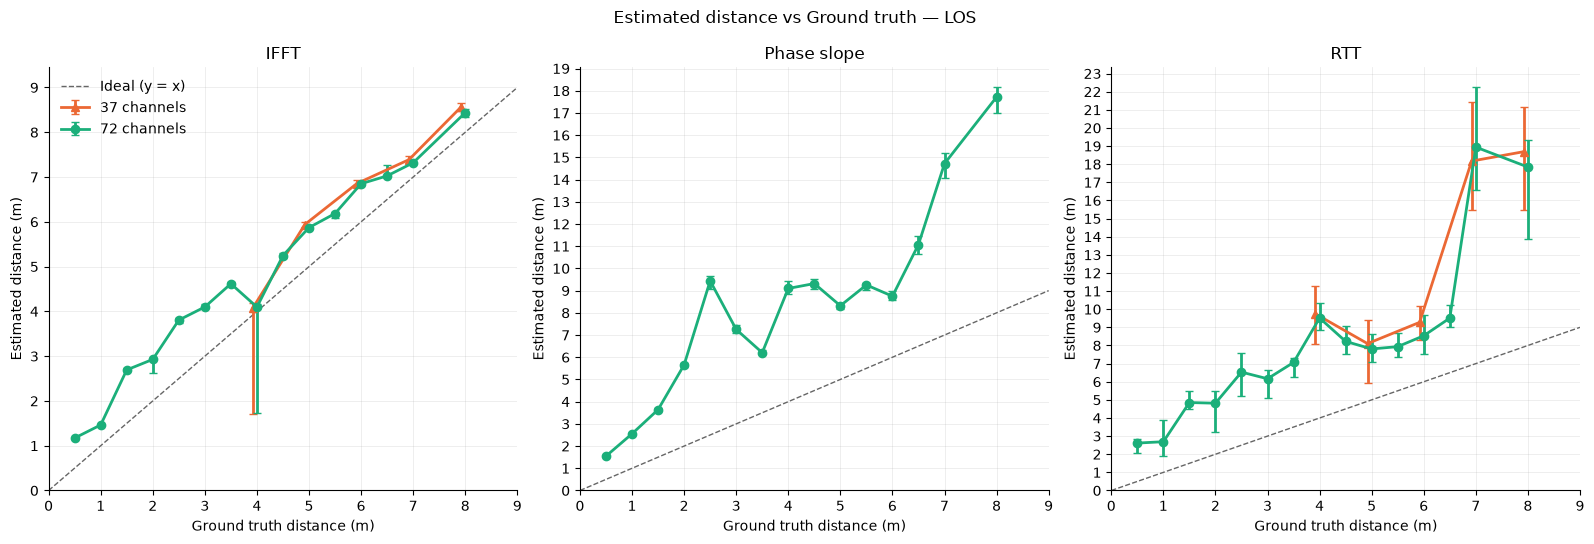

In [57]:
from matplotlib.ticker import MultipleLocator

fig, axes = plt.subplots(1, len(METHOD_ORDER), figsize=(16, 5.5), sharex=True)
lim = [0, d["true_distance_m"].max() + 1]
for ax, method in zip(axes, METHOD_ORDER):
    ax.plot(lim, lim, color="0.4", ls="--", lw=1, label="Ideal (y = x)")
    for n_ch in CHANNEL_COUNTS:
        s = stats[(stats["method"] == method) & (stats["n_channels"] == n_ch)].sort_values("true_distance_m")
        if s.empty:
            continue
        x = s["true_distance_m"] + (CHANNEL_COUNTS.index(n_ch) - 1) * 0.08
        ax.errorbar(
            x, s["median_est_m"],
            yerr=[s["median_est_m"] - s["q25_est_m"], s["q75_est_m"] - s["median_est_m"]],
            color=CH_COLORS.get(n_ch), marker=CH_MARKERS.get(n_ch, "o"), ms=6, lw=2, capsize=3,
            label=f"{n_ch} channels",
        )
    ax.set_title(method)
    ax.set_xlabel("Ground truth distance (m)")
    ax.set_xlim(lim); ax.set_ylim(bottom=0)

    ax.yaxis.set_major_locator(MultipleLocator(1))

    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)

for ax in axes: ax.set_ylabel("Estimated distance (m)")
axes[0].legend(frameon=False)
fig.suptitle(f"Estimated distance vs Ground truth — {ENVIRONMENT or 'All environments'}")
fig.tight_layout()
plt.show()

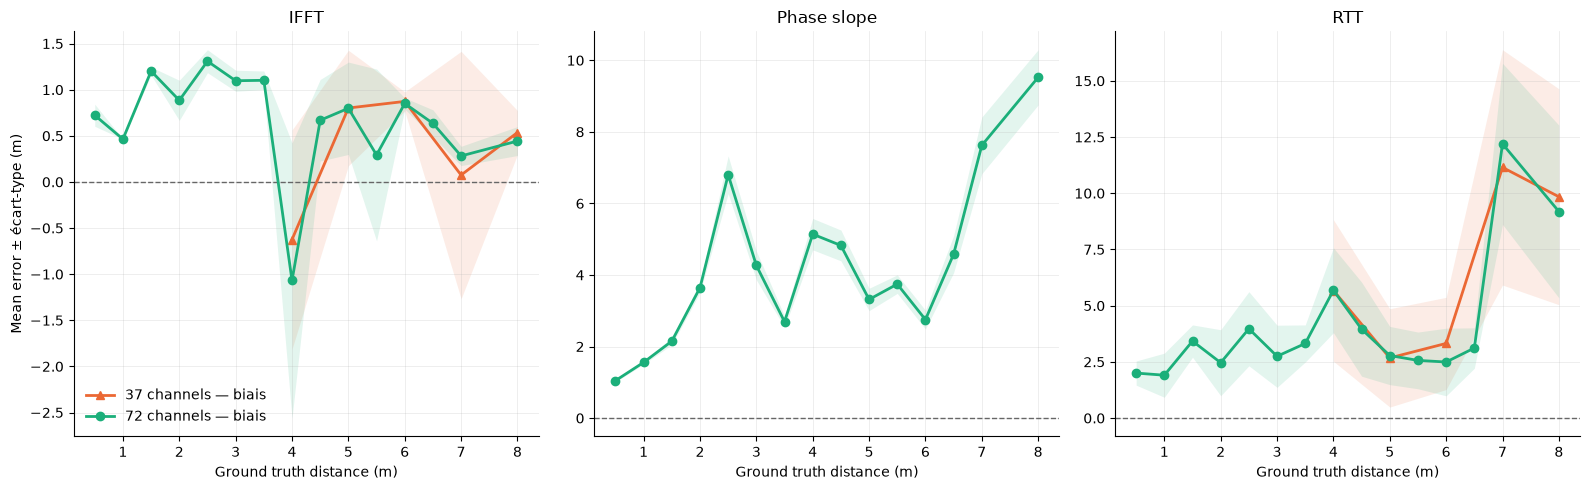

In [34]:
fig, axes = plt.subplots(1, len(METHOD_ORDER), figsize=(16, 5), sharex=True)
for ax, method in zip(axes, METHOD_ORDER):
    ax.axhline(0, color="0.4", ls="--", lw=1)
    for n_ch in CHANNEL_COUNTS:
        s = stats[(stats["method"] == method) & (stats["n_channels"] == n_ch)].sort_values("true_distance_m")
        if s.empty:
            continue
        ax.plot(s["true_distance_m"], s["bias_m"], color=CH_COLORS.get(n_ch), marker=CH_MARKERS.get(n_ch, "o"),
                ms=6, lw=2, label=f"{n_ch} channels — biais")
        ax.fill_between(s["true_distance_m"], s["bias_m"] - s["std_m"], s["bias_m"] + s["std_m"],
                        color=CH_COLORS.get(n_ch), alpha=0.12, lw=0)
    ax.set_title(method)
    ax.set_xlabel("Ground truth distance (m)")
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Mean error ± écart-type (m)")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()